# Classical AI: 🏭 Industry Project: Route Planning and Driver Scheduling (Production-Style)

> **Who is this for?** Anyone who has met search (Dijkstra, A*), local search and constraint satisfaction in theory and
> wonders how a real company uses them. It is also a good revision notebook for exams and interviews, because every
> algorithm is implemented from scratch and checked.
>
> **What you will learn**
> - how to turn a messy road table and a messy order list into a clean, validated road graph
> - point-to-point routing with **Dijkstra** vs. **A\*** (with a provably admissible heuristic): nodes explored and runtime
> - multi-stop routes: a **nearest-neighbour** baseline improved with **2-opt** local search, measured in minutes, km and money
> - driver shift scheduling as a **CSP** solved with **backtracking + MRV + forward checking**, with every rule checked
> - what to do (and what to tell the manager) when the constraints **cannot** all be met
> - how companies run this in production (OR-Tools, solvers, time windows, live re-planning, monitoring)
>
> **Prerequisites**
> - Python basics: [`../../01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb)
> - Search and CSP from this track: [`02_uninformed_search.ipynb`](02_uninformed_search.ipynb), [`03_informed_search.ipynb`](03_informed_search.ipynb), [`04_local_search_and_optimization.ipynb`](04_local_search_and_optimization.ipynb), [`06_constraint_satisfaction.ipynb`](06_constraint_satisfaction.ipynb)
>
> **Time needed:** about 2 hours.
>
> **Runs on:** CPU, no API key, no internet. Only `numpy`, `pandas`, `matplotlib` and `networkx` (used only to check
> our results and to store the graph).
>
> **Optional track:** this notebook is part of the *university-level fundamentals track*. It is not required for the
> main path of the repo, but it is recommended for BS/MS AI students and for interview preparation.

---

### How this notebook is different from the other notebooks in this folder

| Earlier notebooks | This notebook |
|---|---|
| Small textbook graphs (Romania map, 8-puzzle) | A synthetic city with 400 intersections, road types, congestion and closed roads |
| Clean inputs | Duplicated roads, missing speed limits, impossible lengths, duplicated and un-geocoded orders |
| "Which algorithm is optimal?" | "How many minutes, km and dollars does it save per day, and can we trust the answer?" |
| Algorithms in isolation | A pipeline: clean → validate → baseline → better method → measure → check every constraint → report |

---

### The business problem

**Northbridge Parcels** (a fictional company) delivers parcels in a mid-sized city from one depot with **3 vans**.

1. **Routing.** Every morning the dispatcher hands each driver the day's orders in the order they were received, and the
   driver follows that list. Drivers complain about zig-zagging across town. **Goal:** shorter routes (minutes and km)
   without buying software, with routes we can verify.
2. **Scheduling.** The weekly roster for **8 drivers** over 21 shifts (early, late, night × 7 days) is built by hand in a
   spreadsheet. Last month two rosters broke the legal rest rule and one night shift was not covered.
   **Goal:** a roster that provably satisfies every rule, and a clear report when the rules cannot all be met.

**Success metrics:** driving minutes and km per day (and their cost), zero rule violations, solver time of seconds.

### Workflow
```
 raw roads + closures + orders ──> clean & validate ──> road graph
     Part A: Dijkstra vs A* ──> travel-time matrix ──> dispatch-order baseline ──> nearest neighbour ──> 2-opt
             ──> validate against networkx ──> minutes / km / $ saved ──> re-plan after a road closure
     Part B: drivers + rules ──> CSP (backtracking + MRV + forward checking) ──> validate every rule
             ──> infeasible week: diagnose and report ──> production notes
```

## Explained simply

A delivery company has two daily puzzles. First: **which roads should each van take, and in which order should it visit
its stops**, so drivers spend less time on the road? Second: **who works which shift this week**, so every shift is covered
and nobody breaks the rest rules or works too many hours? The first puzzle is solved with *search* (finding the fastest
path on a map) and *local search* (improving a route by small swaps). The second is a *constraint satisfaction problem*:
fill in a timetable so that every rule holds, backing up when you get stuck. We also check every answer carefully,
because a route or roster that breaks a rule is worse than no answer.

- **Everyday example 1:** a map app picking the fastest way home is doing the same kind of search as section 4 and 5.
- **Everyday example 2:** planning a school timetable or a sports league (no team plays two games on the same day) is
  the same kind of puzzle as the driver roster in Part B.

**Tiny concrete example.** A van must visit a bakery, a school and a shop and come back. Driving in the order the orders
arrived (school, shop, bakery) takes 10 + 12 + 9 + 7 = 38 minutes; if the bakery is on the way to the school, the order
bakery, school, shop takes 7 + 5 + 12 + 8 = 32 minutes: same stops, **6 minutes saved** just by changing the order.

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Dijkstra / A* | find the fastest path; A* also "looks towards" the goal | map apps, game characters, robots |
| 2-opt | improve a round trip by undoing crossings | delivery and service routes |
| CSP with backtracking | fill a timetable, backing up when a rule is broken | rosters, exam timetables, sports fixtures |

---
## 1. Setup and config

> 💡 **In plain English:** load the tools and write down every business assumption in one place.

All business assumptions live in one place, so a reviewer can see and change them.

In [1]:
import heapq, itertools, math, random, time, copy      # standard library
from collections import defaultdict, Counter
import numpy as np                                      # numbers
import pandas as pd                                     # tables
import matplotlib.pyplot as plt                         # plots
import networkx as nx                                   # graph container + independent check of our results

SEED = 7
random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.precision", 2); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 120)

CONFIG = {
    "grid_size": 20,                 # 20 x 20 = 400 intersections
    "block_km": 0.35,                # distance between neighbouring intersections
    "speed_kmh": {"residential": 30, "arterial": 50, "expressway": 80},
    "n_vans": 3,
    "service_min_per_stop": 4,       # parking + handing over a parcel (does not depend on the route)
    "driver_cost_per_hour": 35.0,    # assumption, fully loaded cost in $
    "vehicle_cost_per_km": 0.30,     # assumption: fuel + wear in $
    "working_days_per_year": 250,
}
V_MAX = max(CONFIG["speed_kmh"].values())               # fastest legal speed anywhere in the city (km/h)
print(CONFIG); print("V_MAX =", V_MAX, "km/h")

{'grid_size': 20, 'block_km': 0.35, 'speed_kmh': {'residential': 30, 'arterial': 50, 'expressway': 80}, 'n_vans': 3, 'service_min_per_stop': 4, 'driver_cost_per_hour': 35.0, 'vehicle_cost_per_km': 0.3, 'working_days_per_year': 250}
V_MAX = 80 km/h


---
# Part A: Route planning

## 2. Get the data: a messy road table, road closures and orders

> 💡 **In plain English:** build a realistic city and order list, including the mistakes real data always has.

We generate a synthetic city that behaves like a real one:
- a **grid of streets** with random small offsets (no city is perfectly square), some streets missing (parks, rivers);
- **road types** with different speed limits: residential 30 km/h, two arterial roads in each direction (50 km/h) and an
  east-west expressway (80 km/h);
- roads are **curvy**: each road is 0 to 30% longer than the straight line between its intersections;
- **congestion**: arterials in the city centre are slow in the morning (×1.6 travel time);
- the export from the "GIS system" has the problems we always see in real data: **duplicated road segments**, **missing
  speed limits**, **zero or negative lengths**, and **inconsistent spelling** of road types;
- a **road-works list** of closed roads, and an **order list** with duplicates and one address that could not be geocoded.

In [2]:
rng = np.random.default_rng(SEED)
N, S = CONFIG["grid_size"], CONFIG["block_km"]
node_id = lambda r, c: r * N + c                                        # intersection id
coords = {node_id(r, c): (c * S + rng.uniform(-0.08, 0.08), r * S + rng.uniform(-0.08, 0.08))
          for r in range(N) for c in range(N)}                          # (x, y) in km
EXPRESSWAY_ROW, ARTERIALS = 10, {4, 15}
centre = (N - 1) * S / 2

def euclid(a, b):
    (x1, y1), (x2, y2) = coords[a], coords[b]
    return math.hypot(x1 - x2, y1 - y2)

rows = []
for r in range(N):
    for c in range(N):
        for dr, dc in ((0, 1), (1, 0)):                                 # right neighbour and upper neighbour
            r2, c2 = r + dr, c + dc
            if r2 >= N or c2 >= N:
                continue
            u, v = node_id(r, c), node_id(r2, c2)
            if dr == 0 and r == EXPRESSWAY_ROW: rtype = "expressway"
            elif (dr == 0 and r in ARTERIALS) or (dc == 0 and c in ARTERIALS): rtype = "arterial"
            else: rtype = "residential"
            curvy = {"residential": (1.0, 1.3), "arterial": (1.0, 1.1), "expressway": (1.0, 1.05)}[rtype]
            mid = ((coords[u][0] + coords[v][0]) / 2, (coords[u][1] + coords[v][1]) / 2)
            in_centre = math.hypot(mid[0] - centre, mid[1] - centre) < 2.0
            congestion = 1.6 if (rtype == "arterial" and in_centre) else rng.uniform(1.0, 1.2)
            rows.append({"u": u, "v": v, "road_type": rtype, "length_km": euclid(u, v) * rng.uniform(*curvy),
                         "speed_kmh": float(CONFIG["speed_kmh"][rtype]), "congestion": congestion})
roads_true = pd.DataFrame(rows)

# Missing streets: remove 10% of residential segments, but never disconnect the city
G_tmp = nx.Graph(); G_tmp.add_edges_from(zip(roads_true.u, roads_true.v))
drop = []
for idx in rng.permutation(roads_true.index[roads_true.road_type == "residential"])[: int(0.10 * len(roads_true))]:
    u, v = roads_true.loc[idx, ["u", "v"]]
    G_tmp.remove_edge(u, v)
    if nx.is_connected(G_tmp): drop.append(idx)
    else: G_tmp.add_edge(u, v)
roads_true = roads_true.drop(index=drop).reset_index(drop=True)

# ---- Inject the data problems a real export has ----
raw = roads_true.copy()
dups = raw.sample(12, random_state=1).copy(); dups["length_km"] *= rng.uniform(0.98, 1.02, len(dups))   # duplicates
raw = pd.concat([raw, dups], ignore_index=True)
raw.loc[raw.sample(15, random_state=2).index, "speed_kmh"] = np.nan                                     # missing speeds
bad_len = raw.sample(5, random_state=3).index
raw.loc[bad_len[:3], "length_km"] = 0.0; raw.loc[bad_len[3:], "length_km"] = -0.4                      # impossible lengths
messy = raw.sample(20, random_state=4).index
raw.loc[messy, "road_type"] = raw.loc[messy, "road_type"].map(lambda s: rng.choice([s.upper(), s.title() + " ", " " + s]))
raw = raw.sample(frac=1.0, random_state=5).reset_index(drop=True)                                       # random row order

DEPOT = node_id(9, 9)
# Road works: 8 random residential closures + both roads around one small cul-de-sac (an isolated customer)
deg = Counter(list(roads_true.u) + list(roads_true.v))
res = roads_true[roads_true.road_type == "residential"]
victim = next(n for n in rng.permutation(list(coords)) if deg[n] == 2 and n != DEPOT and euclid(n, DEPOT) > 1.0)
victim_edges = roads_true[(roads_true.u == victim) | (roads_true.v == victim)][["u", "v"]].values.tolist()
closures = pd.DataFrame(victim_edges + res.sample(8, random_state=6)[["u", "v"]].values.tolist(), columns=["u", "v"])
closures["reason"] = ["water main repair"] * len(victim_edges) + ["road works"] * 8

# Orders: 36 deliverable orders + 2 duplicated rows, 1 not geocoded, 1 behind the closed roads
order_nodes = [n for n in rng.permutation(list(coords)) if n != DEPOT and n != victim and euclid(n, DEPOT) > 0.5][:36]
orders = pd.DataFrame({"order_id": [f"ORD-{1001 + i}" for i in range(36)], "node": order_nodes,
                       "parcels": rng.integers(1, 4, 36)})
orders = pd.concat([orders,
                    pd.DataFrame({"order_id": ["ORD-1037"], "node": [victim], "parcels": [2]}),
                    pd.DataFrame({"order_id": ["ORD-1038"], "node": [np.nan], "parcels": [1]}),   # failed geocoding
                    orders.iloc[[3, 17]]], ignore_index=True)                                     # duplicated rows
print(f"raw road rows: {len(raw)}, closures: {len(closures)}, raw order rows: {len(orders)}")
raw.head(8)

raw road rows: 696, closures: 10, raw order rows: 40


,u,v,road_type,length_km,speed_kmh,congestion
0,110,130,residential,0.51,30.0,1.18
1,387,388,residential,0.43,30.0,1.15
2,131,132,residential,0.38,30.0,1.13
3,388,389,residential,0.45,30.0,1.16
4,212,213,expressway,0.45,80.0,1.15
5,133,153,Residential,0.47,30.0,1.09
6,21,22,residential,0.41,NaN,1.02
7,149,150,residential,0.39,30.0,1.15


---
## 3. Clean and validate

> 💡 **In plain English:** fix the data problems, count each fix, and prove the properties later steps rely on.

Each fix is counted and printed, because "we silently fixed 17 rows" is how data bugs hide. The validation at the end
is not decoration: the A* heuristic in section 5 is only correct if **every road is at least as long as the straight
line** between its ends and **no road is faster than `V_MAX`**. So we assert exactly those properties.

In [3]:
roads = raw.copy()
report = {}
# 1. normalise spelling of road types
roads["road_type"] = roads["road_type"].str.strip().str.lower()
report["road types re-spelled"] = int((raw["road_type"] != roads["road_type"]).sum())
# 2. duplicates: the same segment listed twice (in any direction) -> keep the first
roads["a"], roads["b"] = roads[["u", "v"]].min(axis=1), roads[["u", "v"]].max(axis=1)
before = len(roads); roads = roads.drop_duplicates(subset=["a", "b"], keep="first"); report["duplicate segments dropped"] = before - len(roads)
# 3. missing speed limits -> default for the road type
miss = roads["speed_kmh"].isna(); report["missing speeds filled"] = int(miss.sum())
roads.loc[miss, "speed_kmh"] = roads.loc[miss, "road_type"].map(CONFIG["speed_kmh"])
# 4. impossible lengths (<= 0) -> recompute from coordinates (straight line: a safe lower bound)
bad = roads["length_km"] <= 0; report["impossible lengths recomputed"] = int(bad.sum())
roads.loc[bad, "length_km"] = [euclid(u, v) for u, v in roads.loc[bad, ["u", "v"]].values]
# 4b. lengths shorter than the straight line are measurement errors (a road cannot be shorter than the crow flies)
short = roads["length_km"] < roads.apply(lambda r: euclid(r.u, r.v), axis=1) - 1e-12
report["too-short lengths raised to straight line"] = int(short.sum())
roads.loc[short, "length_km"] = [euclid(u, v) for u, v in roads.loc[short, ["u", "v"]].values]
# 5. travel time in minutes
roads["minutes"] = roads["length_km"] / roads["speed_kmh"] * 60 * roads["congestion"]
# 6. remove closed roads
closed = set(map(frozenset, closures[["u", "v"]].values.tolist()))
is_closed = roads.apply(lambda r: frozenset((r.u, r.v)) in closed, axis=1)
report["closed segments removed"] = int(is_closed.sum()); roads = roads[~is_closed]

G = nx.Graph()
for r in roads.itertuples():
    G.add_edge(int(r.u), int(r.v), minutes=float(r.minutes), km=float(r.length_km), road_type=r.road_type)
nx.set_node_attributes(G, coords, "pos")
G.add_nodes_from(coords)                                                 # keep isolated intersections as nodes

# ---- Validation (the A* proof depends on these) ----
assert set(roads.road_type) <= set(CONFIG["speed_kmh"]), "unknown road type"
for u, v, d in G.edges(data=True):
    assert d["minutes"] > 0 and d["km"] >= euclid(u, v) - 1e-12
    assert d["km"] / (d["minutes"] / 60) <= V_MAX + 1e-9                  # no road faster than V_MAX
assert not any(G.has_edge(*tuple(e)) for e in closed)

# ---- Orders ----
orders_clean = orders.drop_duplicates(subset="order_id").copy()
report["duplicate orders dropped"] = len(orders) - len(orders_clean)
reachable = nx.node_connected_component(G, DEPOT)
orders_clean["status"] = np.where(orders_clean["node"].isna(), "manual: address not geocoded",
                          np.where(~orders_clean["node"].isin(list(reachable)), "hold: unreachable (road closed)", "ok"))
stops = orders_clean[orders_clean.status == "ok"].copy(); stops["node"] = stops["node"].astype(int)
print(pd.Series(report).to_string())
print(f"\nroad graph: {G.number_of_nodes()} intersections, {G.number_of_edges()} road segments; "
      f"{len(reachable)} intersections reachable from the depot")
print(orders_clean.status.value_counts().to_string())
assert len(stops) == 36 and stops.node.nunique() == 36
orders_clean[orders_clean.status != "ok"]

road types re-spelled                        20
duplicate segments dropped                   12
missing speeds filled                        15
impossible lengths recomputed                 4
too-short lengths raised to straight line     0
closed segments removed                      10
duplicate orders dropped                      2

road graph: 400 intersections, 674 road segments; 399 intersections reachable from the depot
status
ok                                 36
hold: unreachable (road closed)     1
manual: address not geocoded        1


,order_id,node,parcels,status
36,ORD-1037,336.0,2,hold: unreachable (road closed)
37,ORD-1038,NaN,1,manual: address not geocoded


**What just happened?** We fixed 5 kinds of problems and logged each count. Two orders cannot be delivered today and are
**flagged** rather than silently dropped: one address could not be geocoded (a person must fix it), and one customer
lives in a street cut off by the water-main repair (the customer should be contacted). That leaves **36 deliverable
stops**, 12 per van.

> ⚠️ **Common mistake.** Fixing bad lengths by setting them to an average value. Here that could make a road *shorter*
> than the straight line, which silently breaks the A* guarantee. Every repair must keep the invariants that later steps
> rely on, and the invariants must be asserted.

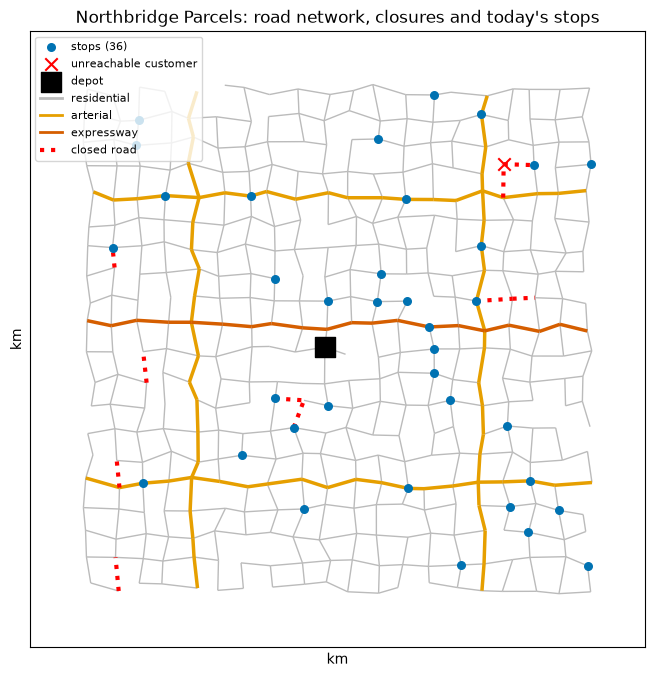

In [4]:
fig, ax = plt.subplots(figsize=(8, 8))
colors = {"residential": "#bbbbbb", "arterial": "#e69f00", "expressway": "#d55e00"}
for rtype, col in colors.items():
    edges = [(u, v) for u, v, d in G.edges(data=True) if d["road_type"] == rtype]
    nx.draw_networkx_edges(G, coords, edgelist=edges, edge_color=col, width=1 if rtype == "residential" else 2.5, ax=ax)
for u, v in closures[["u", "v"]].values:
    ax.plot(*zip(coords[u], coords[v]), color="red", lw=3, ls=":")
ax.scatter(*zip(*[coords[n] for n in stops.node]), s=30, color="#0072b2", zorder=3, label="stops (36)")
ax.scatter(*coords[victim], s=80, marker="x", color="red", zorder=3, label="unreachable customer")
ax.scatter(*coords[DEPOT], s=200, marker="s", color="black", zorder=4, label="depot")
for rtype, col in colors.items():
    ax.plot([], [], color=col, lw=2, label=rtype)
ax.plot([], [], color="red", ls=":", lw=3, label="closed road")
ax.set_title("Northbridge Parcels: road network, closures and today's stops"); ax.set_xlabel("km"); ax.set_ylabel("km")
ax.legend(loc="upper left", fontsize=8); ax.set_aspect("equal"); plt.show()

---
## 4. Point-to-point routing: Dijkstra from scratch

> 💡 **In plain English:** find the fastest way between two points by always growing the closest known area.

**Dijkstra's algorithm** finds the fastest route from one intersection to all others when all travel times are
non-negative. It repeatedly **expands** the unvisited intersection with the smallest known travel time (using a priority
queue), then **relaxes** its roads. Once a node is expanded its time is final.

Time $O((V + E)\log V)$ with a binary heap, space $O(V)$. It explores in **circles** around the start, in every
direction, including away from the destination.

## 5. A*: the same, but aimed at the destination

> 💡 **In plain English:** the same search, but steered towards the destination by a safe guess of the remaining time.

**A\*** expands the node with the smallest $f(n) = g(n) + h(n)$, where $g(n)$ is the travel time so far and $h(n)$ an
estimate of the remaining time. Our heuristic: **straight-line distance divided by the fastest speed in the city**,

$$h(n) = \frac{\text{straight\_line\_km}(n, \text{goal})}{V_{max}} \times 60 \text{ minutes.}$$

**Why it is admissible (never overestimates):** any route from $n$ to the goal is at least as long as the straight line
(triangle inequality, and every road is at least as long as its straight line, which we asserted), and no road is faster
than $V_{max}$ (also asserted; congestion only slows down). So the true time is $\ge h(n)$. It is even **consistent**:
for every road $(u, v)$, $h(u) \le c(u, v) + h(v)$, so A* never needs to re-open a node and returns an optimal route.

> 🎓 **Exam / interview tip.** A heuristic that is admissible today can become inadmissible tomorrow: if the city opens
> a 100 km/h bypass and nobody updates `V_MAX`, A* may return slower routes without any error message. Put the
> assumption in a test (as we did above).

In [5]:
def dijkstra(G, source, target=None, weight="minutes"):
    # returns (dist, parent, expanded_count); stops early when target is expanded
    dist, parent = {source: 0.0}, {source: None}
    pq, done = [(0.0, source)], set()
    while pq:
        d, u = heapq.heappop(pq)                       # closest unexpanded node
        if u in done:
            continue                                   # stale queue entry
        done.add(u)
        if u == target:
            break
        for v, attr in G[u].items():                   # relax every road out of u
            nd = d + attr[weight]
            if nd < dist.get(v, math.inf):
                dist[v], parent[v] = nd, u
                heapq.heappush(pq, (nd, v))
    return dist, parent, done

def astar(G, source, target, h, weight="minutes"):
    g, parent = {source: 0.0}, {source: None}
    pq, done = [(h(source), 0.0, source)], set()
    while pq:
        f, d, u = heapq.heappop(pq)                    # smallest f = g + h
        if u in done:
            continue
        done.add(u)
        if u == target:
            break
        for v, attr in G[u].items():
            nd = d + attr[weight]
            if nd < g.get(v, math.inf):
                g[v], parent[v] = nd, u
                heapq.heappush(pq, (nd + h(v), nd, v))
    return g, parent, done

def path_to(parent, target):
    path = [target]
    while parent[path[-1]] is not None:
        path.append(parent[path[-1]])
    return path[::-1]

def straight_line_heuristic(target, speed=V_MAX):
    tx, ty = coords[target]
    return lambda n: math.hypot(coords[n][0] - tx, coords[n][1] - ty) / speed * 60

# Admissibility and consistency checks (independent of our code: true times from networkx)
for t in random.Random(1).sample(sorted(reachable), 5):
    h = straight_line_heuristic(t)
    true_to_t = nx.single_source_dijkstra_path_length(G, t, weight="minutes")
    assert all(h(n) <= true_to_t[n] + 1e-9 for n in true_to_t)                     # admissible
for u, v, d in G.edges(data=True):                                                  # consistent for ANY goal:
    assert euclid(u, v) / V_MAX * 60 <= d["minutes"] + 1e-9                          # |h(u)-h(v)| <= c(u,v)
print("heuristic is admissible (5 goals, all nodes) and consistent (all edges)")

heuristic is admissible (5 goals, all nodes) and consistent (all edges)


In [6]:
# Compare on 300 random trips; every answer is checked against networkx
pairs_rng = random.Random(2)
nodes_r = sorted(reachable)
rows = []
for _ in range(300):
    s, t = pairs_rng.sample(nodes_r, 2)
    t0 = time.perf_counter(); dd, pd_, done_d = dijkstra(G, s, t); t_d = time.perf_counter() - t0
    t0 = time.perf_counter(); ga, pa, done_a = astar(G, s, t, straight_line_heuristic(t)); t_a = time.perf_counter() - t0
    gw, pw, done_w = astar(G, s, t, straight_line_heuristic(t, speed=30))           # inadmissible: assumes 30 km/h
    ref = nx.dijkstra_path_length(G, s, t, weight="minutes")
    assert abs(dd[t] - ref) < 1e-9 and abs(ga[t] - ref) < 1e-9                        # both optimal
    p = path_to(pa, t); assert abs(sum(G[a][b]["minutes"] for a, b in zip(p, p[1:])) - ref) < 1e-9
    rows.append({"s": s, "t": t, "minutes": ref, "dijkstra_expanded": len(done_d), "astar_expanded": len(done_a),
                 "dijkstra_ms": t_d * 1000, "astar_ms": t_a * 1000, "inadmissible_expanded": len(done_w),
                 "inadmissible_excess_%": (gw[t] - ref) / ref * 100})
trips = pd.DataFrame(rows)
summary = pd.DataFrame({
    "Dijkstra": [trips.dijkstra_expanded.median(), trips.dijkstra_ms.median(), 0.0, 0.0],
    "A* (straight line / 80 km/h)": [trips.astar_expanded.median(), trips.astar_ms.median(), 0.0, 0.0],
    "A* inadmissible (straight line / 30 km/h)": [trips.inadmissible_expanded.median(), np.nan,
        (trips["inadmissible_excess_%"] > 1e-9).mean() * 100, trips["inadmissible_excess_%"].max()],
}, index=["median nodes expanded", "median runtime (ms)", "% trips not optimal", "worst extra time (%)"]).T
print(f"300 trips, median trip {trips.minutes.median():.1f} min; all Dijkstra and A* answers equal networkx.")
summary

300 trips, median trip 8.0 min; all Dijkstra and A* answers equal networkx.


,median nodes expanded,median runtime (ms),% trips not optimal,worst extra time (%)
Dijkstra,202.0,2.48,0.00,0.00
A* (straight line / 80 km/h),109.0,1.58,0.00,0.00
A* inadmissible (straight line / 30 km/h),32.5,NaN,20.67,39.37


median A*/Dijkstra node ratio: 0.57; corner-to-corner trip: 333 vs 385 nodes


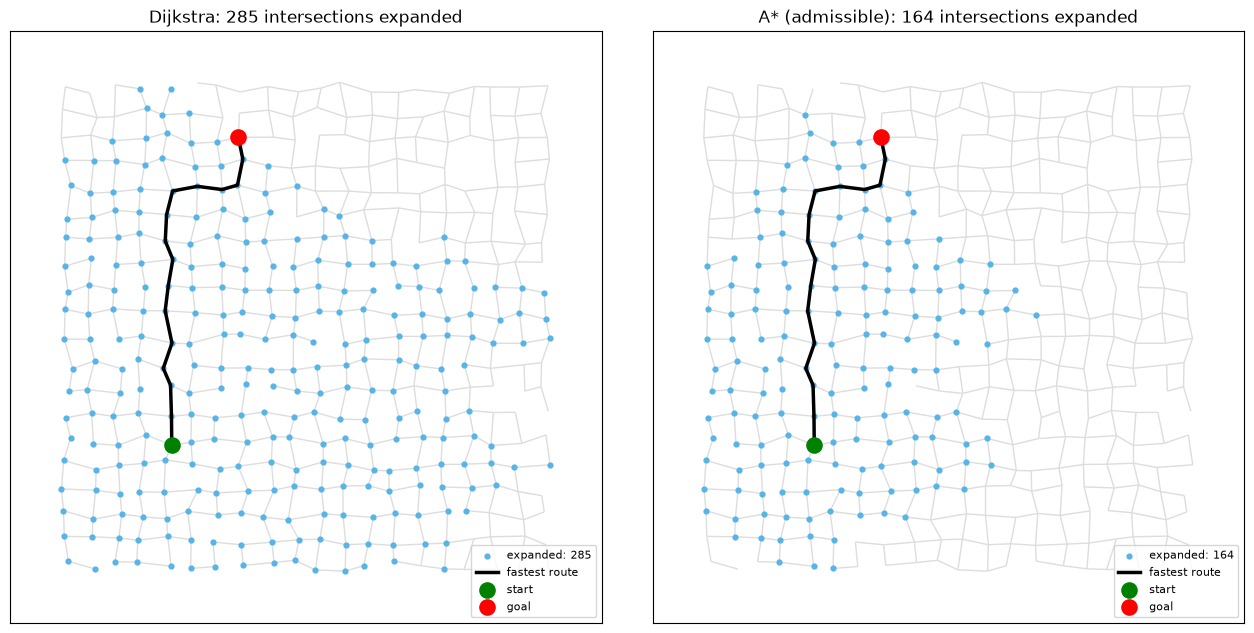

In [7]:
# Visualise a TYPICAL trip: the one whose A*/Dijkstra node ratio is closest to the median ratio (among longer trips)
trips["ratio"] = trips.astar_expanded / trips.dijkstra_expanded
longer = trips[trips.dijkstra_expanded >= trips.dijkstra_expanded.median()]
typical = longer.iloc[(longer.ratio - trips.ratio.median()).abs().argmin()]
s, t = int(typical.s), int(typical.t)
corner_d = len(dijkstra(G, node_id(2, 1), node_id(17, 18))[2])
corner_a = len(astar(G, node_id(2, 1), node_id(17, 18), straight_line_heuristic(node_id(17, 18)))[2])
print(f"median A*/Dijkstra node ratio: {trips.ratio.median():.2f}; corner-to-corner trip: {corner_a} vs {corner_d} nodes")
_, pd1, done1 = dijkstra(G, s, t); _, pa1, done2 = astar(G, s, t, straight_line_heuristic(t))
fig, axes = plt.subplots(1, 2, figsize=(13, 6.3))
for ax, done, par, title in [(axes[0], done1, pd1, "Dijkstra"), (axes[1], done2, pa1, "A* (admissible)")]:
    nx.draw_networkx_edges(G, coords, edge_color="#dddddd", ax=ax)
    ax.scatter(*zip(*[coords[n] for n in done]), s=12, color="#56b4e9", label=f"expanded: {len(done)}")
    p = path_to(par, t)
    ax.plot(*zip(*[coords[n] for n in p]), color="black", lw=2.5, label="fastest route")
    ax.scatter(*coords[s], s=120, color="green", zorder=3, label="start"); ax.scatter(*coords[t], s=120, color="red", zorder=3, label="goal")
    ax.set_title(f"{title}: {len(done)} intersections expanded"); ax.set_aspect("equal"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

**What just happened?**
- Both algorithms returned the **same, optimal** travel time on all 300 trips (checked against `networkx`), and the path
  A* returned really has that travel time.
- A* expanded about half as many intersections as Dijkstra (median 109 vs. 202) and was faster too, because it is
  pulled towards the goal: in the picture Dijkstra grows a "circle" around the start, A* a narrower region aimed at the
  goal. On a long corner-to-corner trip the gain is much smaller (printed above the picture): the heuristic assumes
  80 km/h everywhere, while most streets allow 30, so it underestimates a lot and A* falls back towards Dijkstra.
- The heuristic is weak in one way: it assumes we could drive at 80 km/h in a straight line, while most roads allow 30.
  Pretending every road is 30 km/h (an **inadmissible** heuristic) explores even fewer nodes, but some trips are then
  **not optimal** (see the last row). This is a legitimate engineering trade-off (*weighted A\**), but it must be a
  conscious decision with a measured worst case, not an accident.

**Complexity.** Both are $O((V + E) \log V)$ in the worst case; A* with a consistent heuristic never expands more nodes
than Dijkstra (up to ties). Production routing engines (OSRM, Valhalla, GraphHopper) precompute **contraction hierarchies**
or similar structures so that a city-to-city query takes milliseconds on continental road networks.

---
## 6. Multi-stop routes: from the dispatch list to nearest neighbour to 2-opt

> 💡 **In plain English:** choose a good order for a van's stops: start greedy, then fix crossings.

Each van must leave the depot, visit its 12 stops and come back: a **travelling salesman problem (TSP)**, which is
NP-hard. 12 stops already have $11!/2 \approx 20$ million possible tours (we will brute-force smaller cases to measure
how good our heuristics are).

Steps:
1. **Assign stops to vans** with a simple **sweep**: sort stops by their angle around the depot and cut them into 3
   groups of 12 (a classic first step in vehicle routing).
2. **Travel-time matrix:** one Dijkstra from the depot and from every stop gives the fastest time between every pair
   (and the actual road path for each leg).
3. **Baseline 0, today's practice:** visit the stops in the order the orders arrived.
4. **Baseline 1, nearest neighbour (NN):** always drive to the closest unvisited stop. Greedy, $O(n^2)$.
5. **2-opt local search:** take two roads of the tour, $(a \to b)$ and $(c \to d)$, and reconnect them as $(a \to c)$ and
   $(b \to d)$, reversing the part in between. Keep the change if the tour gets shorter; repeat until no such move helps
   (a **local optimum**). On a symmetric matrix the gain of a move is computed in $O(1)$:
   $\Delta = c(a,c) + c(b,d) - c(a,b) - c(c,d)$. One full pass is $O(n^2)$.

```
 before:  a → b → x → y → c → d          after 2-opt:  a → c → y → x → b → d
              └── crossing ──┘                            (segment b..c reversed, the crossing disappears)
```

In [8]:
# 1. Sweep assignment
ang = {n: math.atan2(coords[n][1] - coords[DEPOT][1], coords[n][0] - coords[DEPOT][0]) for n in stops.node}
by_angle = sorted(stops.node, key=ang.get)
k = len(by_angle) // CONFIG["n_vans"]
van_stops = {f"van {i + 1}": by_angle[i * k:(i + 1) * k] for i in range(CONFIG["n_vans"])}
# within each van keep the dispatch order (order_id) for the baseline
dispatch_rank = {n: i for i, n in enumerate(stops.sort_values("order_id").node)}
van_stops = {v: sorted(ns, key=dispatch_rank.get) for v, ns in van_stops.items()}

# 2. Travel-time matrix + leg paths, from one Dijkstra per point
def build_matrix(points):
    n = len(points)
    D, legs = np.zeros((n, n)), {}
    for i, p in enumerate(points):
        dist, parent, _ = dijkstra(G, p)                                  # one-to-all
        for j, q in enumerate(points):
            D[i, j] = dist[q]
            legs[(i, j)] = path_to(parent, q)
    return D, legs

def tour_cost(tour, D):
    return sum(D[a, b] for a, b in zip(tour, tour[1:]))

def nearest_neighbour(D):
    n = len(D); tour, left = [0], set(range(1, n))
    while left:
        nxt = min(left, key=lambda j: D[tour[-1], j])                     # closest unvisited stop
        tour.append(nxt); left.remove(nxt)
    return tour + [0]

def two_opt(tour, D):
    tour, improved, passes = list(tour), True, 0
    while improved:
        improved, passes = False, passes + 1
        for i in range(1, len(tour) - 2):
            for j in range(i + 1, len(tour) - 1):
                a, b, c, d = tour[i - 1], tour[i], tour[j], tour[j + 1]
                delta = D[a, c] + D[b, d] - D[a, b] - D[c, d]             # O(1) gain of the move
                if delta < -1e-9:
                    tour[i:j + 1] = reversed(tour[i:j + 1])               # reverse the segment b..c
                    improved = True
    return tour, passes

def expand_km(tour, legs):
    # full road path of a tour and its length in km
    path = [legs[(0, 0)][0]]
    for a, b in zip(tour, tour[1:]):
        path += legs[(a, b)][1:]
    return path, sum(G[u][v]["km"] for u, v in zip(path, path[1:]))

results, plans = [], {}
for van, ns in van_stops.items():
    points = [DEPOT] + ns
    D, legs = build_matrix(points)
    assert np.allclose(D, D.T)                                            # undirected roads: symmetric matrix
    for i, j in [(0, 5), (3, 7), (11, 2)]:                                # spot-check against networkx
        assert abs(D[i, j] - nx.dijkstra_path_length(G, points[i], points[j], weight="minutes")) < 1e-9
    tours = {"dispatch order (today)": list(range(len(points))) + [0], "nearest neighbour": nearest_neighbour(D)}
    tours["NN + 2-opt"], passes = two_opt(tours["nearest neighbour"], D)
    tours["dispatch order + 2-opt"], _ = two_opt(tours["dispatch order (today)"], D)
    plans[van] = {"points": points, "D": D, "legs": legs, "tours": tours}
    for name, tour in tours.items():
        path, km = expand_km(tour, legs)
        results.append({"van": van, "method": name, "drive_min": tour_cost(tour, D), "km": km})
res = pd.DataFrame(results)
table = res.pivot_table(index="method", values=["drive_min", "km"], aggfunc="sum").loc[
    ["dispatch order (today)", "nearest neighbour", "NN + 2-opt", "dispatch order + 2-opt"]]
table["vs today (min)"] = table.drive_min - table.loc["dispatch order (today)", "drive_min"]
table["vs today (%)"] = table["vs today (min)"] / table.loc["dispatch order (today)", "drive_min"] * 100
print("All 3 vans together, one day:")
table

All 3 vans together, one day:


,drive_min,km,vs today (min),vs today (%)
method,,,,
dispatch order (today),198.41,120.53,0.00,0.00
nearest neighbour,112.64,64.01,-85.77,-43.23
NN + 2-opt,111.43,63.37,-86.98,-43.84
dispatch order + 2-opt,111.57,63.99,-86.83,-43.77


In [9]:
# Validate every planned route (independently of how it was built)
for van, plan in plans.items():
    pts, D, legs = plan["points"], plan["D"], plan["legs"]
    for name, tour in plan["tours"].items():
        assert tour[0] == 0 and tour[-1] == 0                                       # starts and ends at the depot
        assert sorted(tour[1:-1]) == list(range(1, len(pts)))                       # every stop exactly once
        path, km = expand_km(tour, legs)
        for u, v in zip(path, path[1:]):
            assert G.has_edge(u, v) and frozenset((u, v)) not in closed            # only open, existing roads
        drive = sum(G[u][v]["minutes"] for u, v in zip(path, path[1:]))
        assert abs(drive - tour_cost(tour, D)) < 1e-6                               # matrix cost = real road cost
        for a, b in zip(tour, tour[1:]):                                            # each leg is a fastest path
            assert abs(D[a, b] - nx.dijkstra_path_length(G, pts[a], pts[b], weight="minutes")) < 1e-9
print("all", sum(len(p["tours"]) for p in plans.values()), "routes validated against the graph and networkx")

# How far from optimal are NN and 2-opt? Brute force on 60 random 7-stop instances (7! = 5040 tours each)
gap_rows, rr = [], random.Random(3)
for _ in range(60):
    pts = [DEPOT] + rr.sample(list(stops.node), 7)
    D_small, _ = build_matrix(pts)
    best = min(tour_cost([0, *perm, 0], D_small) for perm in itertools.permutations(range(1, 8)))
    nn = nearest_neighbour(D_small); opt2, _ = two_opt(nn, D_small)
    gap_rows.append({"NN gap %": (tour_cost(nn, D_small) / best - 1) * 100, "NN+2-opt gap %": (tour_cost(opt2, D_small) / best - 1) * 100})
gaps = pd.DataFrame(gap_rows)
assert (gaps >= -1e-9).all().all()                                                  # never better than optimal
print(gaps.describe().loc[["mean", "50%", "max"]].round(2).to_string())
print(f"2-opt found the optimum in {(gaps['NN+2-opt gap %'] < 1e-9).mean():.0%} of the instances")

all 12 routes validated against the graph and networkx


      NN gap %  NN+2-opt gap %
mean      6.21            0.78
50%       5.58            0.00
max      18.67            6.81
2-opt found the optimum in 68% of the instances


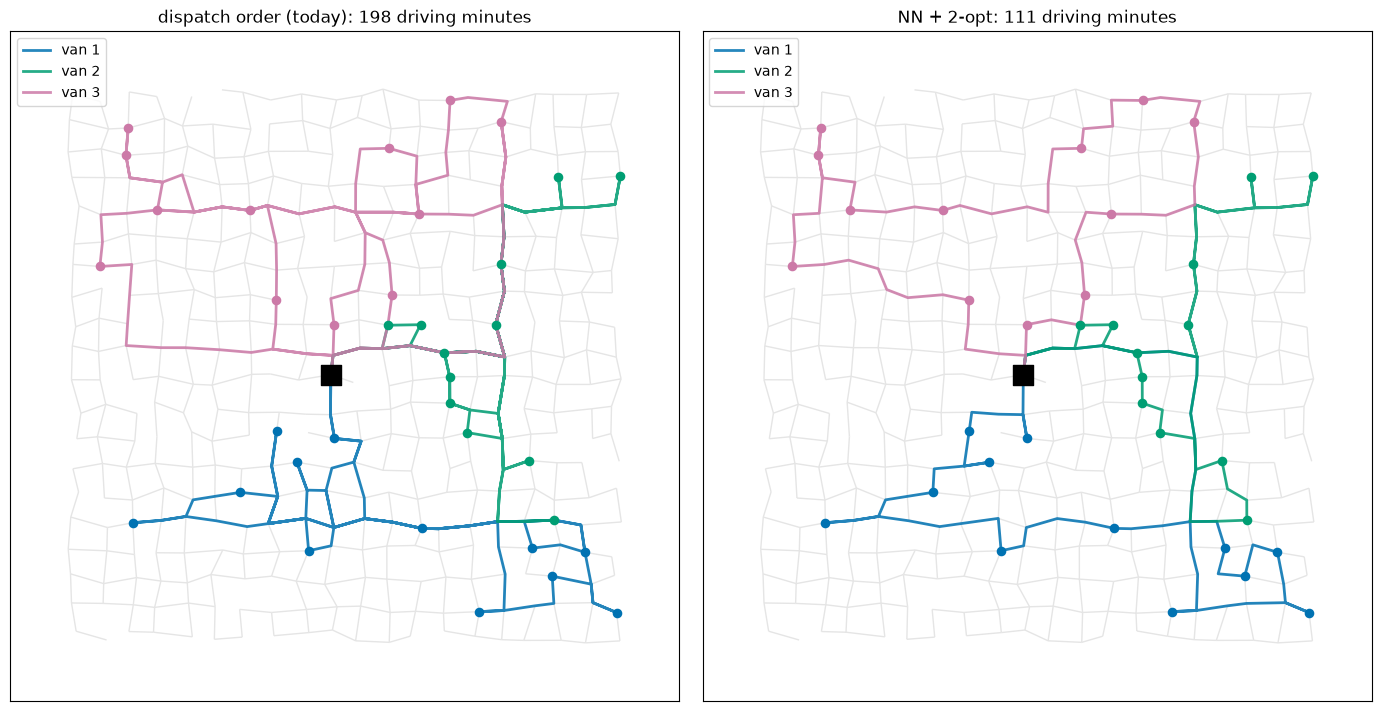

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
van_colors = ["#0072b2", "#009e73", "#cc79a7"]
for ax, method in zip(axes, ["dispatch order (today)", "NN + 2-opt"]):
    nx.draw_networkx_edges(G, coords, edge_color="#e5e5e5", ax=ax)
    total = 0
    for (van, plan), col in zip(plans.items(), van_colors):
        path, km = expand_km(plan["tours"][method], plan["legs"])
        total += tour_cost(plan["tours"][method], plan["D"])
        ax.plot(*zip(*[coords[n] for n in path]), color=col, lw=2, alpha=0.85, label=van)
        ax.scatter(*zip(*[coords[n] for n in plan["points"][1:]]), color=col, s=35, zorder=3)
    ax.scatter(*coords[DEPOT], s=200, marker="s", color="black", zorder=4)
    ax.set_title(f"{method}: {total:.0f} driving minutes"); ax.set_aspect("equal"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

In [11]:
# The business result
today = table.loc["dispatch order (today)"]; best = table.loc["NN + 2-opt"]
saved_min, saved_km = today.drive_min - best.drive_min, today.km - best.km
day_cost = saved_min / 60 * CONFIG["driver_cost_per_hour"] + saved_km * CONFIG["vehicle_cost_per_km"]
year = day_cost * CONFIG["working_days_per_year"]
service = CONFIG["service_min_per_stop"] * len(stops)
print(f"Driving time: {today.drive_min:.0f} -> {best.drive_min:.0f} min per day ({saved_min:.0f} min saved, {saved_min / today.drive_min:.0%})")
print(f"Distance:     {today.km:.1f} -> {best.km:.1f} km per day ({saved_km:.1f} km saved)")
print(f"Value:        ${day_cost:.0f} per day, about ${year:,.0f} per year (assumptions in CONFIG)")
for van, plan in plans.items():
    shift = tour_cost(plan["tours"]["NN + 2-opt"], plan["D"]) + CONFIG["service_min_per_stop"] * (len(plan["points"]) - 1)
    print(f"  {van}: route + service = {shift:.0f} min (fits in an 8-hour shift: {shift <= 480})")
assert saved_min > 0 and best.drive_min <= table.loc["nearest neighbour"].drive_min + 1e-9

Driving time: 198 -> 111 min per day (87 min saved, 44%)
Distance:     120.5 -> 63.4 km per day (57.2 km saved)
Value:        $68 per day, about $16,971 per year (assumptions in CONFIG)
  van 1: route + service = 88 min (fits in an 8-hour shift: True)
  van 2: route + service = 80 min (fits in an 8-hour shift: True)
  van 3: route + service = 87 min (fits in an 8-hour shift: True)


**What just happened?**
- The dispatch-order routes zig-zag across each van's area. **Nearest neighbour** already removes most of the waste,
  and **2-opt** removes the remaining crossings. For the three vans together, driving time drops from about 198 to 111
  minutes per day (44%) and distance from about 121 to 63 km, worth roughly $68 per day or $17,000 per year with our cost
  assumptions. The savings are large because "the order in which orders arrived" has nothing to do with geography.
- 2-opt started from the bad dispatch order also improves a lot, but usually ends in a *different* local optimum.
  Local search depends on its starting point; that is why production solvers start from a good constructive
  solution and use metaheuristics (guided local search, simulated annealing) to escape local optima.
- On 60 small instances where we could brute-force the optimum, NN was on average several percent above optimal and
  NN + 2-opt was very close (often exactly optimal). This is the typical picture in the literature too.
- Every route was validated: it starts and ends at the depot, visits each stop once, uses only open roads, and its
  cost equals the sum of real road travel times.

**Complexity.** Matrix: $n+1$ Dijkstra runs, $O(n (V+E)\log V)$. NN: $O(n^2)$. 2-opt: $O(n^2)$ per pass, usually a few
passes. Brute force: $O(n!)$, only possible for tiny $n$.

> ⚠️ **Common mistake.** Reporting "km saved" when the algorithm optimised **minutes**. Here we minimise time; the km
> saving is a side effect and could, in principle, be negative (a faster route can be longer). Always report what you
> optimised, and the other KPIs separately.

### 6.1 Re-planning after a road closure
At 10:40 the city closes a road that van 1's planned route uses. Production systems re-plan immediately: remove the
road, recompute the affected travel times, and re-optimise the stops that are not yet visited.

In [12]:
plan = plans["van 1"]
path, _ = expand_km(plan["tours"]["NN + 2-opt"], plan["legs"])
# close the road used on the longest stretch of the route, i.e. the edge with most travel time
u_c, v_c = max(zip(path, path[1:]), key=lambda e: G[e[0]][e[1]]["minutes"])
old_minutes = tour_cost(plan["tours"]["NN + 2-opt"], plan["D"])
G_backup = G[u_c][v_c].copy(); G.remove_edge(u_c, v_c)                     # the closure
try:
    D_new, legs_new = build_matrix(plan["points"])
    old_tour_new_cost = tour_cost(plan["tours"]["NN + 2-opt"], D_new)      # keep the old order, take detours
    new_tour, _ = two_opt(plan["tours"]["NN + 2-opt"], D_new)              # re-optimise the order as well
    new_path, _ = expand_km(new_tour, legs_new)
    assert all(frozenset(e) != frozenset((u_c, v_c)) for e in zip(new_path, new_path[1:]))   # closed road avoided
    print(f"closed road {u_c}-{v_c} ({G_backup['road_type']}, {G_backup['minutes']:.2f} min)")
    print(f"planned: {old_minutes:.1f} min | same order with detours: {old_tour_new_cost:.1f} min | re-optimised: {tour_cost(new_tour, D_new):.1f} min")
finally:
    G.add_edge(u_c, v_c, **G_backup)                                       # restore the network for later cells

closed road 189-169 (residential, 1.43 min)
planned: 40.4 min | same order with detours: 43.7 min | re-optimised: 43.7 min


**What just happened?** The closure costs some extra minutes. Re-running 2-opt on the new matrix either finds a better
order or confirms that the current order is still the best local option. In production this runs on events (closure,
accident, a failed delivery) or on a timer, for the stops not yet visited; the stop a driver is already driving to is
usually **frozen** so the plan does not flip-flop under the driver.

---
# Part B: Driver shift scheduling as a constraint satisfaction problem

## 7. The rules, written down precisely

> 💡 **In plain English:** turn the roster rules into a puzzle a computer can solve, and solve it.

| # | Rule | Type |
|---|---|---|
| C1 | **Coverage**: each shift gets exactly the required number of drivers (weekdays: early 2, late 2, night 1; Saturday: 1/2/1; Sunday: 1/1/1) | hard |
| C2 | **Availability**: days off, night-capable drivers only on nights, Hana works only late shifts (childcare) | hard (unary) |
| C3 | **One shift per day** per driver | hard |
| C4 | **Max hours**: 8-hour shifts; full-time max 40 h (5 shifts), part-time max 24 h (3 shifts) | hard |
| C5 | **No back-to-back night shifts** (company policy) | hard |
| C6 | **11-hour rest** between shifts (legal): early 06-14, late 14-22, night 22-06. So no early after a late or a night, and no late after a night | hard |

**CSP formulation.**
- **Variables:** one per *slot*: (day, shift, position), e.g. (Mon, Early, 0) and (Mon, Early, 1). 32 slots.
- **Domains:** the drivers allowed in that slot after applying C2 (unary constraints are applied once, up front:
  **node consistency**).
- **Constraints:** C3 to C6 between slots, plus a symmetry-breaking rule: in a shift with two positions, position 0
  gets the alphabetically smaller name (otherwise the solver would explore "Ali + Bea" and "Bea + Ali" as different
  schedules).

**Solver:** depth-first **backtracking** with
- **MRV** (minimum remaining values): fill the slot with the fewest possible drivers first ("fail first");
- **forward checking**: after each assignment, remove from the other slots every driver that is no longer allowed; if a
  slot has nobody left, backtrack immediately;
- two cheap **look-ahead checks**: total remaining capacity $\ge$ remaining slots, and on every day the unfilled slots
  can still get *different* drivers;
- **value ordering**: try the driver with the fewest shifts so far first (spreads the work, and leaves options open).

In [13]:
DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
SHIFTS = ["Early", "Late", "Night"]
SHIFT_HOURS = {"Early": "06-14", "Late": "14-22", "Night": "22-06"}
DRIVERS = {
    "Ali":    {"max_shifts": 5, "nights": True,  "off_days": {"Sun"},        "only_shifts": None},
    "Bea":    {"max_shifts": 5, "nights": True,  "off_days": {"Sat"},        "only_shifts": None},
    "Chen":   {"max_shifts": 5, "nights": False, "off_days": set(),          "only_shifts": None},
    "Dana":   {"max_shifts": 5, "nights": True,  "off_days": {"Wed"},        "only_shifts": None},
    "Emeka":  {"max_shifts": 5, "nights": False, "off_days": {"Sun"},        "only_shifts": None},
    "Fatima": {"max_shifts": 5, "nights": True,  "off_days": {"Mon"},        "only_shifts": None},
    "Goran":  {"max_shifts": 3, "nights": False, "off_days": {"Mon", "Tue"}, "only_shifts": None},   # part-time
    "Hana":   {"max_shifts": 3, "nights": False, "off_days": {"Sat", "Sun"}, "only_shifts": {"Late"}},  # part-time
}
COVER = {d: {"Early": 2, "Late": 2, "Night": 1} for d in DAYS[:5]}
COVER["Sat"] = {"Early": 1, "Late": 2, "Night": 1}
COVER["Sun"] = {"Early": 1, "Late": 1, "Night": 1}
# (shift on day d, shift on day d+1) pairs that are forbidden: rest rule C6 + no back-to-back nights C5
FORBIDDEN_NEXT = {("Late", "Early"): "C6 rest", ("Night", "Early"): "C6 rest", ("Night", "Late"): "C6 rest",
                  ("Night", "Night"): "C5 back-to-back nights"}

def available(dr, day, shift, drivers):
    info = drivers[dr]
    return not (day in info["off_days"] or (shift == "Night" and not info["nights"])
                or (info["only_shifts"] is not None and shift not in info["only_shifts"]))

print(f"slots to fill: {sum(sum(c.values()) for c in COVER.values())}, "
      f"driver capacity: {sum(d['max_shifts'] for d in DRIVERS.values())} shifts")

slots to fill: 32, driver capacity: 36 shifts


In [14]:
class RosterCSP:
    def __init__(self, drivers, cover, mrv=True, fc=True, lookahead=True, balance=True, node_limit=10_000, rng=None):
        self.drivers, self.cover, self.limit, self.rng = drivers, cover, node_limit, rng
        self.mrv, self.fc, self.lookahead, self.balance = mrv, fc, lookahead, balance
        self.vars = [(d, s, k) for d in DAYS for s in SHIFTS for k in range(cover[d][s])]       # the slots
        self.domains = {v: [dr for dr in drivers if available(dr, v[0], v[1], drivers)] for v in self.vars}  # C2
        self.assign = {}                                          # slot -> driver
        self.week = {dr: {} for dr in drivers}                    # driver -> {day index: shift}, for O(1) checks
        self.nodes = self.backtracks = 0

    def consistent(self, var, dr):
        d, s, k = var; i = DAYS.index(d); wk = self.week[dr]
        if i in wk: return False                                                # C3 one shift per day
        if len(wk) >= self.drivers[dr]["max_shifts"]: return False              # C4 max hours
        if i - 1 in wk and (wk[i - 1], s) in FORBIDDEN_NEXT: return False       # C5/C6 with the day before
        if i + 1 in wk and (s, wk[i + 1]) in FORBIDDEN_NEXT: return False       # C5/C6 with the day after
        for k2 in range(self.cover[d][s]):                                      # symmetry breaking in a shift
            other = self.assign.get((d, s, k2))
            if other is not None and ((k2 < k and not other < dr) or (k2 > k and not dr < other)):
                return False
        return True

    def select_variable(self, domains):
        unassigned = [v for v in self.vars if v not in self.assign]
        if not self.mrv:
            return unassigned[0]                                                # static order: Monday first
        best = min(len(domains[v]) for v in unassigned)                         # MRV
        ties = [v for v in unassigned if len(domains[v]) == best]
        return self.rng.choice(ties) if self.rng else ties[0]

    def order_values(self, var, domains):
        vals = list(domains[var])
        if self.rng: self.rng.shuffle(vals)
        return sorted(vals, key=lambda dr: len(self.week[dr])) if self.balance else vals

    def forward_check(self, var, dr, domains):
        # remove values that became inconsistent; only driver dr's state changed, plus same-day slots (symmetry/C3)
        new = dict(domains)
        for v in self.vars:
            if v in self.assign: continue
            if v[0] == var[0] or dr in domains[v]:
                new[v] = [x for x in domains[v] if self.consistent(v, x)]
                if not new[v]:
                    return None                                                  # domain wipe-out: dead end
        return new

    def look_ahead_ok(self, domains):
        unassigned = [v for v in self.vars if v not in self.assign]
        if sum(self.drivers[x]["max_shifts"] - len(self.week[x]) for x in self.drivers) < len(unassigned):
            return False                                                         # not enough capacity left
        for day in DAYS:                                                         # each day needs distinct drivers
            slots = [v for v in unassigned if v[0] == day]
            if slots and len(set().union(*[domains[v] for v in slots])) < len(slots):
                return False
        return True

    def solve(self):
        return self._bt({v: list(d) for v, d in self.domains.items()})

    def _bt(self, domains):
        if len(self.assign) == len(self.vars):
            return dict(self.assign)                                             # complete and consistent
        if self.nodes >= self.limit:
            return None                                                          # give up (reported as 'limit')
        var = self.select_variable(domains)
        for dr in self.order_values(var, domains):
            self.nodes += 1
            if not self.consistent(var, dr):
                continue
            self.assign[var] = dr; self.week[dr][DAYS.index(var[0])] = var[1]
            new = self.forward_check(var, dr, domains) if self.fc else domains
            if new is not None and (not self.lookahead or self.look_ahead_ok(new)):
                result = self._bt(new)
                if result:
                    return result
            del self.assign[var]; del self.week[dr][DAYS.index(var[0])]          # undo and try the next driver
            self.backtracks += 1
        return None

csp = RosterCSP(DRIVERS, COVER)
t0 = time.perf_counter(); schedule = csp.solve(); t_solve = time.perf_counter() - t0
print(f"solved: {schedule is not None}, nodes: {csp.nodes}, backtracks: {csp.backtracks}, time: {t_solve * 1000:.0f} ms")

solved: True, nodes: 39, backtracks: 7, time: 37 ms


In [15]:
def validate(schedule, drivers, cover):
    # independent checker: does NOT reuse the solver's code. Raises AssertionError with the broken rule.
    week = defaultdict(dict)
    for (d, s, k), dr in schedule.items():
        assert available(dr, d, s, drivers), f"C2 availability: {dr} on {d} {s}"
        assert d not in week[dr], f"C3 two shifts on {d} for {dr}"
        week[dr][d] = s
    for d in DAYS:
        for s in SHIFTS:
            assigned = [dr for (d2, s2, _), dr in schedule.items() if (d2, s2) == (d, s)]
            assert len(assigned) == cover[d][s] and len(set(assigned)) == len(assigned), f"C1 coverage {d} {s}"
    for dr, wk in week.items():
        assert len(wk) <= drivers[dr]["max_shifts"], f"C4 {dr} works {len(wk) * 8} h"
        for d1, d2 in zip(DAYS, DAYS[1:]):
            if d1 in wk and d2 in wk:
                assert (wk[d1], wk[d2]) not in FORBIDDEN_NEXT, f"{FORBIDDEN_NEXT.get((wk[d1], wk[d2]))}: {dr} {d1}->{d2}"
    return True

assert validate(schedule, DRIVERS, COVER)
# the checker must also CATCH violations: break the schedule on purpose in 3 ways
broken = dict(schedule); slot = next(v for v in broken if v[1] == "Night"); broken[slot] = "Hana"
busiest, n_busiest = Counter(schedule.values()).most_common(1)[0]
stricter = copy.deepcopy(DRIVERS); stricter[busiest]["max_shifts"] = n_busiest - 1      # same roster, tighter contract
for name, bad, drv in [("Hana on a night", broken, DRIVERS),
                       ("a slot left empty", dict(list(schedule.items())[1:]), DRIVERS),
                       (f"{busiest} over contract hours", schedule, stricter)]:
    try:
        validate(bad, drv, COVER); raise RuntimeError("validator missed a violation")
    except AssertionError as e:
        print(f"validator caught '{name}': {e}")

roster = pd.DataFrame("-", index=list(DRIVERS), columns=DAYS)
for (d, s, k), dr in schedule.items():
    roster.loc[dr, d] = s
roster["shifts"] = (roster[DAYS] != "-").sum(axis=1)
roster["hours"] = roster["shifts"] * 8
roster["max hours"] = [DRIVERS[d]["max_shifts"] * 8 for d in roster.index]
roster

validator caught 'Hana on a night': C2 availability: Hana on Mon Night
validator caught 'a slot left empty': C1 coverage Mon Night
validator caught 'Bea over contract hours': C4 Bea works 40 h


,Mon,Tue,Wed,Thu,Fri,Sat,Sun,shifts,hours,max hours
Ali,Night,-,Early,Early,Night,-,-,4,32,40
Bea,Early,Night,-,Late,Late,-,Night,5,40,40
Chen,Late,-,Late,-,Early,Early,Early,5,40,40
Dana,-,Early,-,Night,-,Night,-,3,24,40
Emeka,Early,Early,-,Late,Late,Late,-,5,40,40
Fatima,-,Late,Night,-,Early,Late,-,4,32,40
Goran,-,-,Early,Early,-,-,Late,3,24,24
Hana,Late,Late,Late,-,-,-,-,3,24,24


**What just happened?** The solver filled all 32 slots after exploring only a few dozen nodes, in milliseconds. The
**validator** is written independently of the solver (it re-derives every rule from the schedule itself) and confirms
C1 to C6. We also checked that the validator **catches** violations, by breaking the schedule on purpose: a validator
that never fails proves nothing. The table is what the manager sees: one row per driver, hours vs. contract.

Let us measure what MRV and forward checking actually buy, on this week and on two busier weeks (more coverage at the
weekend). Every run gets the same budget of 10,000 nodes.

In [16]:
WEEKS = {
    "normal week (32 slots)": COVER,
    "busy weekend (34 slots)": {**COVER, "Sat": {"Early": 2, "Late": 2, "Night": 1}, "Sun": {"Early": 1, "Late": 2, "Night": 1}},
    "very busy weekend (35 slots)": {**COVER, "Sat": {"Early": 2, "Late": 2, "Night": 1}, "Sun": {"Early": 2, "Late": 2, "Night": 1}},
}
CONFIGS = {
    "plain backtracking": dict(mrv=False, fc=False, lookahead=False, balance=False),
    "+ MRV": dict(mrv=True, fc=False, lookahead=False, balance=False),
    "+ forward checking": dict(mrv=False, fc=True, lookahead=False, balance=False),
    "MRV + FC": dict(mrv=True, fc=True, lookahead=False, balance=False),
    "MRV + FC + look-ahead + balance": dict(mrv=True, fc=True, lookahead=True, balance=True),
}

def solve_with_restarts(drivers, cover, seed=0, limit=1000, max_restarts=30):
    # randomised tie-breaking + restarts: cut off unlucky runs early and try again
    rng, total = random.Random(seed), 0
    for r in range(max_restarts):
        s = RosterCSP(drivers, cover, node_limit=limit, rng=rng)
        res = s.solve(); total += s.nodes
        if res: return res, total, r + 1
    return None, total, max_restarts

rows, found = [], {}
for week, cover in WEEKS.items():
    for name, kw in CONFIGS.items():
        s = RosterCSP(DRIVERS, cover, **kw); t0 = time.perf_counter(); res = s.solve(); el = time.perf_counter() - t0
        if res: validate(res, DRIVERS, cover)
        rows.append({"week": week, "solver": name, "solved": res is not None, "nodes": s.nodes, "ms": el * 1000,
                     "cell": f"{s.nodes} nodes" + ("" if res else " (gave up)")})
    t0 = time.perf_counter(); res, total, n_restarts = solve_with_restarts(DRIVERS, cover); el = time.perf_counter() - t0
    assert res is not None and validate(res, DRIVERS, cover); found[week] = res
    rows.append({"week": week, "solver": "MRV + FC + look-ahead + balance + restarts", "solved": True, "nodes": total,
                 "ms": el * 1000, "cell": f"{total} nodes ({n_restarts} run{'s' if n_restarts > 1 else ''})"})
bench = pd.DataFrame(rows)
print(f"total benchmark time: {bench.ms.sum() / 1000:.1f} s")
bench.pivot_table(index="solver", columns="week", values="cell", aggfunc="first", sort=False)[list(WEEKS)]

total benchmark time: 8.0 s


week,normal week (32 slots),busy weekend (34 slots),very busy weekend (35 slots)
solver,,,
plain backtracking,955 nodes,10078 nodes (gave up),10068 nodes (gave up)
+ MRV,120 nodes,149 nodes,10054 nodes (gave up)
+ forward checking,155 nodes,5939 nodes,10041 nodes (gave up)
MRV + FC,40 nodes,10037 nodes (gave up),10038 nodes (gave up)
MRV + FC + look-ahead + balance,39 nodes,1376 nodes,10039 nodes (gave up)
MRV + FC + look-ahead + balance + restarts,33 nodes (1 run),311 nodes (1 run),1127 nodes (2 runs)


**What just happened?** (Numbers = nodes explored; "gave up" = hit the 10,000-node budget without a schedule.)
- On the **normal week**, MRV + forward checking needs a few dozen nodes where plain backtracking needs hundreds. This
  is the textbook result: fail first, detect dead ends early.
- On the **busier weeks** the picture is not so simple. Some combinations that are excellent on the normal week give up
  on a busy week. The cause is **thrashing**: an early, unlucky decision (e.g. who covers Tuesday night) makes the rest
  impossible, but the conflict is only discovered much deeper, and chronological backtracking keeps re-trying the
  irrelevant decisions in between. Search time on such problems has a **heavy tail**: most runs are fast, a few are
  extremely slow.
- **Randomised restarts** (Gomes, Selman and Kautz, 1998) exploit exactly this: cap each run at 1,000 nodes, and if it
  fails, restart with different random tie-breaking. This solves all three weeks with a small total effort.
- Every schedule found was checked by the independent validator.

The honest conclusion for the business: our from-scratch solver is fine for 8 drivers, but its runtime is not
predictable on tight weeks. Production schedulers use solvers with **conflict-driven learning** and restarts built in
(CP-SAT); see section 9.

**Complexity.** Backtracking is $O(d^n)$ in the worst case for $n$ slots and $d$ drivers (CSP is NP-complete in
general); MRV, forward checking and look-ahead do not change the worst case, they shrink the tree that is actually
explored. Forward checking costs $O(n d)$ per node here.

## 8. When the rules cannot all be met: diagnose and report

> 💡 **In plain English:** explain clearly why no roster exists and offer concrete ways out.

Next week **Chen, Emeka and Goran** have all requested **Saturday off** (a family event and a football final). Pressing
"solve" and showing "no solution" is useless to a manager. A good system:
1. runs cheap **necessary-condition checks** first, each tied to a human-readable reason;
2. runs the solver (which proves infeasibility by exhausting the search, if the checks did not already);
3. proposes **concrete options** and re-solves with the chosen one.

In [17]:
def precheck(drivers, cover):
    # necessary conditions; each failure is a human-readable reason
    issues = []
    total_slots = sum(sum(c.values()) for c in cover.values())
    capacity = sum(d["max_shifts"] for d in drivers.values())
    if capacity < total_slots:
        issues.append({"check": "weekly capacity", "where": "whole week", "required": total_slots, "available": capacity,
                       "detail": f"need {total_slots - capacity} more driver shifts"})
    for day in DAYS:
        need = sum(cover[day].values())
        people = [dr for dr in drivers if any(available(dr, day, s, drivers) for s in SHIFTS)]
        if len(people) < need:                                          # one shift per day -> distinct drivers
            issues.append({"check": "distinct drivers per day", "where": day, "required": need, "available": len(people),
                           "detail": "available: " + ", ".join(people)})
        for s in SHIFTS:
            ok = [dr for dr in drivers if available(dr, day, s, drivers)]
            if len(ok) < cover[day][s]:
                issues.append({"check": "drivers allowed on this shift", "where": f"{day} {s}", "required": cover[day][s],
                               "available": len(ok), "detail": "allowed: " + (", ".join(ok) or "nobody")})
    return pd.DataFrame(issues)

drivers_leave = copy.deepcopy(DRIVERS)
for name in ["Chen", "Emeka", "Goran"]:
    drivers_leave[name]["off_days"] |= {"Sat"}

issues = precheck(drivers_leave, COVER)
s_inf = RosterCSP(drivers_leave, COVER, node_limit=50_000)
t0 = time.perf_counter(); res_inf = s_inf.solve(); el = time.perf_counter() - t0
print(f"solver result: {'schedule found' if res_inf else 'NO SCHEDULE EXISTS'} "
      f"(search exhausted after {s_inf.nodes} nodes, {el * 1000:.0f} ms; limit not reached: {s_inf.nodes < s_inf.limit})")
assert res_inf is None and s_inf.nodes < s_inf.limit and len(issues) > 0
issues

solver result: NO SCHEDULE EXISTS (search exhausted after 3 nodes, 4 ms; limit not reached: True)


,check,where,required,available,detail
0,distinct drivers per day,Sat,4,3,"available: Ali, Dana, Fatima"


In [18]:
# Options for the manager, each re-solved and validated
options = {}
# Option A: book one agency driver for Saturday (early or late only)
drivers_a = copy.deepcopy(drivers_leave)
drivers_a["Agency-1"] = {"max_shifts": 1, "nights": False, "off_days": set(DAYS) - {"Sat"}, "only_shifts": {"Early", "Late"}}
# Option B: reduce Saturday late coverage from 2 to 1 (fewer afternoon deliveries)
cover_b = copy.deepcopy(COVER); cover_b["Sat"]["Late"] = 1
# Option C: refuse one of the three leave requests (Goran works Saturday after all)
drivers_c = copy.deepcopy(drivers_leave); drivers_c["Goran"]["off_days"] -= {"Sat"}

rows = []
for label, drv, cov in [("A: book 1 agency driver for Saturday", drivers_a, COVER),
                        ("B: Saturday late shift with 1 driver", drivers_leave, cover_b),
                        ("C: decline Goran's Saturday leave", drivers_c, COVER)]:
    pre = precheck(drv, cov)
    res, nodes, runs = solve_with_restarts(drv, cov, seed=1)
    if res: validate(res, drv, cov)
    options[label] = res
    rows.append({"option": label, "pre-check issues": len(pre), "schedule found": res is not None,
                 "solver nodes": nodes,
                 "cost / impact": {"A": "agency rate for 8 h", "B": "fewer Saturday afternoon deliveries",
                                   "C": "one unhappy driver"}[label[0]]})
opt_table = pd.DataFrame(rows)
assert opt_table["schedule found"].all()
opt_table

,option,pre-check issues,schedule found,solver nodes,cost / impact
0,A: book 1 agency driver for Saturday,0,True,34,agency rate for 8 h
1,B: Saturday late shift with 1 driver,0,True,36,fewer Saturday afternoon deliveries
2,C: decline Goran's Saturday leave,0,True,35,one unhappy driver


**What just happened?**
- The pre-check found the root cause in microseconds: Saturday needs **4 different drivers** (1 early, 2 late, 1 night,
  one shift per person per day) but only **3** are available (Ali, Dana, Fatima). The detail column names them, so the
  manager immediately understands the problem.
- The solver independently **proved** that no schedule exists (it exhausted the search well within its budget,
  thanks to the look-ahead check). Never report "infeasible" when the solver merely hit a time limit: that is
  "unknown", and the message to the manager must say so.
- Three options were re-solved and each schedule validated. Choosing between them is a **business** decision (cost vs.
  service vs. staff goodwill); the system's job is to make the trade-off explicit.

> ⚠️ **Common mistake.** Turning every hard rule into a soft penalty so that "the solver always returns something". Then
> a legal rule like the 11-hour rest can be broken silently. Keep legal rules hard; make *business wishes* (fairness,
> preferences) soft and optimise them separately, and report infeasibility honestly.

---
## 9. How companies run this in production

> 💡 **In plain English:** the tools, extra rules and monitoring real delivery companies use.

**Routing**
- **Road data and travel times** come from a routing engine (OSRM, Valhalla or GraphHopper on OpenStreetMap data, or a
  commercial API) that answers many-to-many travel-time matrix queries in milliseconds using precomputed hierarchies.
  Travel times depend on the **time of day** (historical speed profiles) and are refreshed with **live traffic**.
- **Optimisation** uses a vehicle-routing solver rather than hand-written 2-opt: **Google OR-Tools** (open source,
  routing library and the CP-SAT solver), commercial solvers (e.g. Gurobi, Hexaly) or planning engines such as
  Timefold (the continuation of OptaPlanner). They handle the real constraints:
  - **VRPTW** (vehicle routing with **time windows**: "deliver between 9 and 11"), van **capacities** (weight, volume),
    driver breaks, multiple depots, pickups and deliveries, priorities, and *which van gets which stop* jointly with the
    order (our sweep split was a simplification);
  - they use the same ideas as this notebook: a constructive first solution (like NN or "cheapest insertion"), then local
    search moves (2-opt, or-opt, relocate, exchange) inside a metaheuristic (guided local search, simulated annealing,
    large neighbourhood search) with a time limit.
- **Re-planning**: event-driven (closure, accident, failed delivery, new urgent order) or every few minutes, only for
  stops not yet visited, with the next stop **frozen**. Big changes need a dispatcher's approval.

**Scheduling**
- Rostering is usually solved with **CP-SAT** or a MIP solver: hard rules (law, contracts) as constraints, wishes
  (fairness, preferences, overtime cost) in the objective. Solvers return **"optimal", "feasible", "infeasible" or
  "unknown"** and many can explain infeasibility (e.g. an infeasible subset of constraints or assumptions), which feeds
  a report like section 8.

**Monitoring and governance**

| What to monitor | Why |
|---|---|
| planned vs. actual drive time per route (ETA error) | detects stale travel-time data |
| on-time delivery rate, failed deliveries | the real customer KPI |
| km and drive minutes per stop, per van | the cost KPI that justified the project |
| solver runtime, status (optimal / feasible / unknown / infeasible) | catches "unknown" being reported as "infeasible" |
| number of manual overrides by dispatchers | high numbers mean the model misses a real rule |
| rule violations in published rosters (must be 0) | legal compliance, run the validator on every publish |
| data quality counts from section 3 | a spike in "missing speeds" or "duplicate segments" means the upstream export broke |

**Limits of this notebook:** synthetic city and orders; one depot; no time windows, capacities or breaks; symmetric
travel times (one-way streets make the matrix asymmetric, and our O(1) 2-opt gain formula would then be wrong because
reversing a segment changes its cost); deterministic travel times; a fixed sweep assignment of stops to vans; and our
cost figures are assumptions.

## 🔗 How this connects to modern AI
- **Search** (Dijkstra, A*) runs inside every map app and robot path planner; A*-style best-first search with learned
  heuristics appears in game AI and in planning for LLM agents ([`../../10_Agents/02_memory_and_planning.ipynb`](../../10_Agents/02_memory_and_planning.ipynb)).
- **Local search** (2-opt) is the same idea as gradient-free optimisation and hyper-parameter search; learning-based
  routing (graph neural networks that propose moves) is an active research area but production systems still rely on
  classical solvers.
- **CSP solvers** schedule shifts, exams, sports leagues, cloud jobs and GPU clusters. LLM agents increasingly
  *call* such solvers as tools instead of trying to reason out a schedule in text, because only the solver can
  guarantee every rule.
- **Forecasting feeds optimisation**: demand forecasts decide the coverage numbers that the roster must meet
  ([`../../04_Forecasting/12_industry_call_center_staffing_forecast.ipynb`](../../04_Forecasting/12_industry_call_center_staffing_forecast.ipynb)).

## Recap
- Clean and **validate** the data first; the invariants (length $\ge$ straight line, speed $\le V_{max}$) are exactly what
  makes A*'s heuristic admissible.
- **Dijkstra** and **A\*** give the same optimal answer; A* with an admissible, consistent heuristic explores fewer nodes.
  An inadmissible heuristic is faster but can be wrong; measure how wrong.
- Multi-stop routes: **nearest neighbour** is a good start, **2-opt** fixes crossings; together they removed most of the
  waste of the dispatch-order routes, and were close to optimal on small brute-forced cases.
- Scheduling as a **CSP**: slots as variables, drivers as values, rules as constraints. **MRV + forward checking**
  (+ look-ahead) shrink the search tree; **randomised restarts** tame the heavy tail on tight weeks.
- Validate every constraint with an **independent checker**, and test that the checker catches violations.
- Infeasible? Run cheap **pre-checks** that explain *why*, distinguish "proven infeasible" from "gave up", and offer options.
- In production: OR-Tools / CP-SAT or commercial solvers, time windows (VRPTW), live re-planning, and monitoring.

## Practice problems

**1. (Easy, conceptual)** The city opens a 100 km/h bypass but nobody updates `V_MAX = 80`. Is A* still guaranteed to be
optimal? What would you add to the pipeline to prevent this?

<details><summary>Show solution</summary>

No. On the bypass, real travel can be faster than "straight line / 80 km/h", so $h$ can overestimate and A* may return a
slower route. Compute `V_MAX` from the data (`max(speeds)`) instead of hard-coding it, and keep the assertion from
section 3 (`km / hours <= V_MAX` for every road), which would fail loudly.
</details>

**2. (Easy, coding)** Show that A* with $h(n) = 0$ behaves exactly like Dijkstra: same cost and same number of expanded
nodes on 50 random trips.

<details><summary>Show solution</summary>

```python
r = random.Random(9)
for _ in range(50):
    s, t = r.sample(nodes_r, 2)
    d1, _, e1 = dijkstra(G, s, t)
    d2, _, e2 = astar(G, s, t, lambda n: 0.0)
    assert abs(d1[t] - d2[t]) < 1e-9 and len(e1) == len(e2)
print("A* with h = 0 is Dijkstra")
```
</details>

**3. (Medium, conceptual)** Derive the 2-opt gain $\Delta = c(a,c) + c(b,d) - c(a,b) - c(c,d)$. Why is it wrong when
the travel-time matrix is asymmetric (one-way streets)?

<details><summary>Show solution</summary>

The move removes roads $a \to b$ and $c \to d$ and adds $a \to c$ and $b \to d$; all other roads are kept. With a
symmetric matrix the reversed segment $c \to \dots \to b$ costs the same as $b \to \dots \to c$, so only the four end
roads change. With an asymmetric matrix every road inside the segment is now driven in the opposite direction, so the
gain must also include $\sum (c(y, x) - c(x, y))$ over the segment: $O(n)$ per move, or use moves that do not reverse
segments (or-opt, relocate).
</details>

**4. (Medium, coding)** Implement **or-opt**: try moving each single stop to every other position in the tour and keep
improving moves until none is left. Run it after 2-opt on every van. Does it ever make a tour worse? Does it help?

<details><summary>Show solution</summary>

```python
def or_opt(tour, D):
    tour, improved = list(tour), True
    while improved:
        improved = False
        for i in range(1, len(tour) - 1):
            for j in range(1, len(tour) - 1):
                if j in (i, i - 1):
                    continue
                cand = tour[:i] + tour[i + 1:]                  # remove stop at position i
                pos = j if j < i else j - 1
                cand = cand[:pos + 1] + [tour[i]] + cand[pos + 1:]   # insert it after position pos
                if tour_cost(cand, D) < tour_cost(tour, D) - 1e-9:
                    tour, improved = cand, True
                    break
            if improved:
                break
    return tour

for van, plan in plans.items():
    t2 = plan["tours"]["NN + 2-opt"]; t3 = or_opt(t2, plan["D"])
    assert sorted(t3[1:-1]) == sorted(t2[1:-1]) and tour_cost(t3, plan["D"]) <= tour_cost(t2, plan["D"]) + 1e-9
    print(van, round(tour_cost(t2, plan["D"]), 2), "->", round(tour_cost(t3, plan["D"]), 2))
```
It never makes a tour worse (it only accepts improving moves). Whether it helps depends on the instance: 2-opt and or-opt
explore different neighbourhoods, so combining them can only reach an equal or better local optimum.
</details>

**5. (Medium, coding)** Write `weekend_rest_ok(schedule)` that checks a new rule: "every driver has at least one of
Saturday or Sunday off". Does our normal-week schedule satisfy it?

<details><summary>Show solution</summary>

```python
def weekend_rest_ok(schedule):
    works = defaultdict(set)
    for (d, s, k), dr in schedule.items():
        works[dr].add(d)
    bad = [dr for dr, days in works.items() if {"Sat", "Sun"} <= days]
    return len(bad) == 0, bad

print(weekend_rest_ok(schedule))
```
The answer depends on the schedule the solver happened to find (in our run it returns `(False, ['Chen'])`: Chen works
both Saturday and Sunday); to *guarantee* the rule, add it as a constraint in
`consistent` (a driver already working Saturday cannot take Sunday and vice versa).
</details>

**6. (Medium, conceptual)** Why do randomised restarts help backtracking search, and why must the cut-off not be too small?

<details><summary>Show solution</summary>

Backtracking runtimes on hard CSPs are **heavy-tailed**: a bad early choice leads to a huge subtree with no solution
(thrashing), while many other early choices lead quickly to a solution. Restarting with different random tie-breaking
after a cut-off abandons the unlucky runs. If the cut-off is smaller than the effort a *lucky* run needs, no run can
ever finish, so the cut-off must be above the typical successful run length (strategies such as Luby's sequence grow it
automatically). Restarts make the search incomplete unless the cut-off grows, so to *prove* infeasibility you need a
complete run (or a pre-check), as in section 8.
</details>

**7. (Hard, conceptual)** The weekly capacity check passes (36 shifts ≥ 32 slots) and every day has enough distinct
drivers, yet a roster might still be impossible. Give an example of a rule interaction that the pre-checks miss, and
how you would detect it.

<details><summary>Show solution</summary>

Night shifts: with the rest rule, a night on day $d$ forbids any shift on day $d+1$, and nights cannot be back-to-back.
If only two drivers can do nights and their days off fall badly, 7 nights may be impossible even though every single
night has an allowed driver and total capacity is fine. Pre-checks only test necessary conditions one at a time; the
interaction is found by the solver (exhaustive search proves infeasibility) or by a stronger check, e.g. computing the
maximum number of nights each night-capable driver can work under the rest rules and comparing the sum with 7.
Production solvers report an infeasible subset of constraints to explain such cases.
</details>

## Further reading
- Russell and Norvig, *AIMA* 4th ed.: ch. 3 (search, A* and admissibility), ch. 4 (local search), ch. 6 (constraint
  satisfaction: MRV, forward checking, backtracking).
- Toth and Vigo (eds.), *Vehicle Routing: Problems, Methods, and Applications* (2nd ed., 2014).
- Gomes, Selman and Kautz, "Boosting combinatorial search through randomization" (AAAI 1998) on heavy tails and restarts.
- Free online: the Google OR-Tools documentation (developers.google.com/optimization), with routing (VRP, VRPTW) and
  employee-scheduling examples; and Amit Patel's "Introduction to A*" (Red Blob Games).

## Next notebook
This is the last notebook of the **Classical AI** module. Continue with the data structures and algorithms module
([`../dsa/01_complexity_analysis_and_recursion.ipynb`](../dsa/01_complexity_analysis_and_recursion.ipynb)), or go back to
[`09_uncertain_knowledge_and_reasoning.ipynb`](09_uncertain_knowledge_and_reasoning.ipynb) for probabilistic reasoning.